In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("./housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df = df.dropna()
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_household"] = df["total_bedrooms"] / df["households"]
df["population_per_household"] = df["population"] / df["households"]

In [5]:
X = df.drop(columns="median_house_value")
y = df["median_house_value"]

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(x_train.shape,y_train.shape)
print(x_test.shape,y_test.shape)

(16346, 12) (16346,)
(4087, 12) (4087,)


In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20433 non-null  float64
 1   latitude                  20433 non-null  float64
 2   housing_median_age        20433 non-null  float64
 3   total_rooms               20433 non-null  float64
 4   total_bedrooms            20433 non-null  float64
 5   population                20433 non-null  float64
 6   households                20433 non-null  float64
 7   median_income             20433 non-null  float64
 8   median_house_value        20433 non-null  float64
 9   ocean_proximity           20433 non-null  str    
 10  rooms_per_household       20433 non-null  float64
 11  bedrooms_per_household    20433 non-null  float64
 12  population_per_household  20433 non-null  float64
dtypes: float64(12), str(1)
memory usage: 2.3 MB


In [7]:
x_train_prep = x_train.copy()
x_test_prep = x_test.copy()

drop_cols = ["total_rooms", "total_bedrooms", "population"]
x_train_prep = x_train_prep.drop(columns=drop_cols)
x_test_prep = x_test_prep.drop(columns=drop_cols)

In [8]:
skewed_cols = ["households", "rooms_per_household", "bedrooms_per_household", "population_per_household"]
for col in skewed_cols:
    x_train_prep[col] = np.log1p(x_train_prep[col])
    x_test_prep[col] = np.log1p(x_test_prep[col])

encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
encoder.set_output(transform="pandas")

train_cat = encoder.fit_transform(x_train_prep[["ocean_proximity"]]) # fit_transform learns also
test_cat = encoder.transform(x_test_prep[["ocean_proximity"]])

In [9]:
x_train_prep = pd.concat([x_train_prep.drop(columns=["ocean_proximity"]), train_cat], axis=1)
x_test_prep = pd.concat([x_test_prep.drop(columns=["ocean_proximity"]), test_cat], axis=1)

# scale mean 0 variance 1
num_cols = [col for col in x_train_prep.columns if not col.startswith("ocean_proximity_")] # not the hot encoded ones
scaler = StandardScaler()
x_train_prep[num_cols] = scaler.fit_transform(x_train_prep[num_cols])
x_test_prep[num_cols] = scaler.transform(x_test_prep[num_cols])

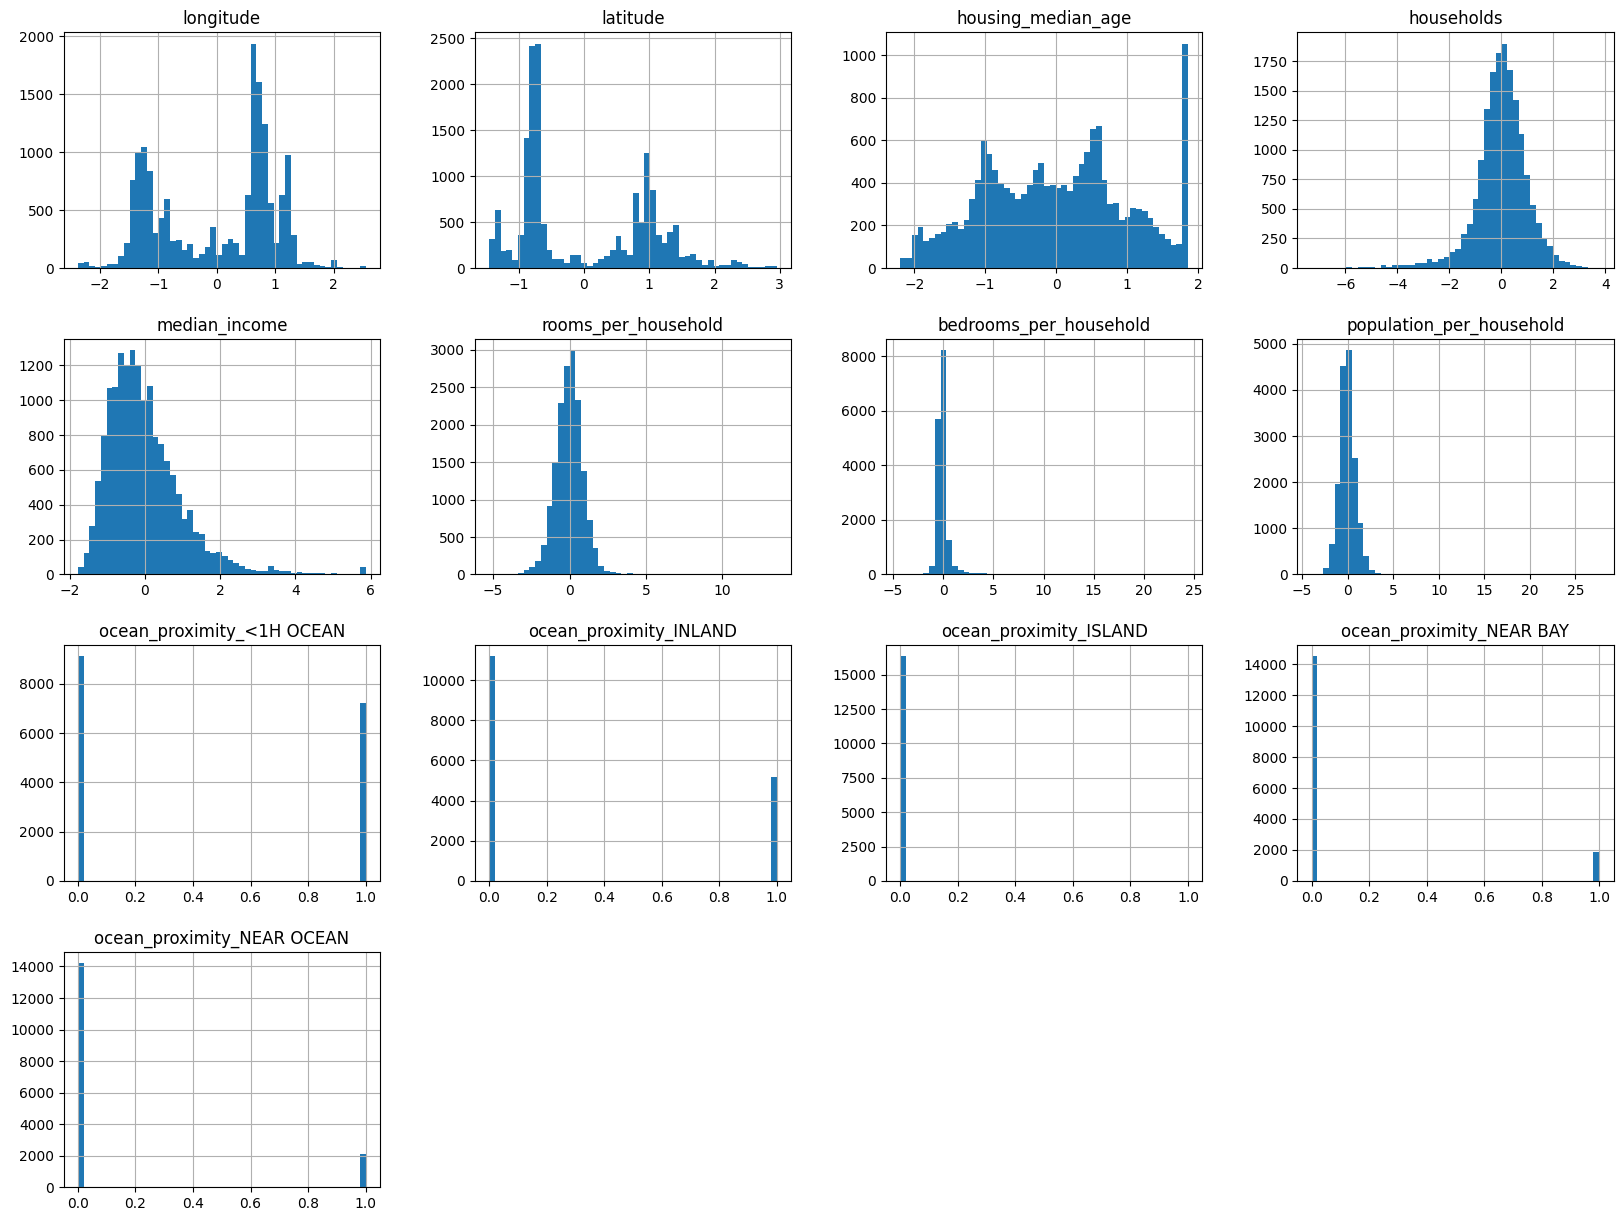

In [10]:
x_train_prep.hist(bins=50,figsize=(20,15))
plt.show()

In [11]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error, r2_score

In [12]:
y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

svr = SVR(kernel="rbf", C=10.0, epsilon=0.1)
svr.fit(x_train_prep, y_train_scaled)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [13]:
y_pred_scaled = svr.predict(x_test_prep)
y_pred = y_scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()

In [14]:
print(f"rmse :- {root_mean_squared_error(y_test, y_pred)}")
print(f"r2 :- {r2_score(y_test, y_pred)}")

rmse :- 53184.20452528414
r2 :- 0.7931610809947809


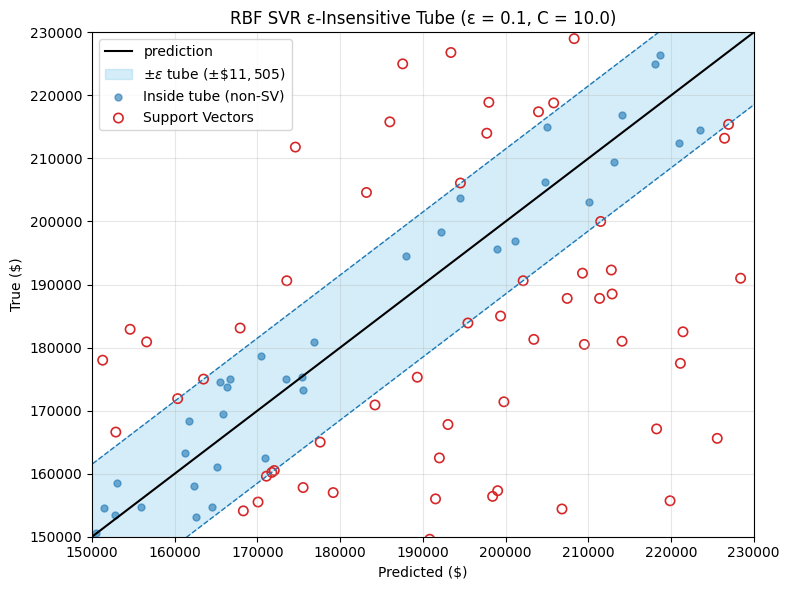

In [ ]:
y_train_arr = np.asarray(y_train).ravel()
y_train_pred = y_scaler.inverse_transform(
    svr.predict(x_train_prep).reshape(-1, 1)
).ravel()

eps_dollars = svr.epsilon * y_scaler.scale_[0]

is_sv = np.zeros(len(y_train_arr), dtype=bool)
is_sv[svr.support_] = True

rng = np.random.default_rng(42)
idx = rng.choice(len(y_train_arr), size=400, replace=False)

pred_sub = y_train_pred[idx]
true_sub = y_train_arr[idx]
sv_sub = is_sv[idx]

fig, ax = plt.subplots(figsize=(8, 6))

grid = np.linspace(pred_sub.min(), pred_sub.max(), 200)
ax.plot(grid, grid, color="black", lw=1.5, label="prediction")
ax.fill_between(
    grid,
    grid - eps_dollars,
    grid + eps_dollars,
    color="skyblue",
    alpha=0.35,
    label=rf"$\pm\varepsilon$ tube ($\pm\${eps_dollars:,.0f}$)"
)
ax.plot(grid, grid + eps_dollars, color="tab:blue", ls="--", lw=1)
ax.plot(grid, grid - eps_dollars, color="tab:blue", ls="--", lw=1)

# non SVs
ax.scatter(
    pred_sub[~sv_sub], true_sub[~sv_sub],
    color="tab:blue", alpha=0.6, s=25, label="Inside tube (non-SV)"
)

# SVs
ax.scatter(
    pred_sub[sv_sub], true_sub[sv_sub],
    facecolors="none", edgecolors="tab:red", s=45, lw=1.2, label="Support Vectors"
)

ax.set_xlabel("Predicted ($)")
ax.set_ylabel("True ($)")
ax.set_xlim(150_000, 230_000)
ax.set_ylim(150_000, 230_000)
ax.set_title(f"RBF SVR ε-Insensitive Tube (ε = {svr.epsilon}, C = {svr.C})")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()